# House Price Prediction with Regression

**Problem:** Predict the price of a house from its features.

**Data:** 20,000 houses (`house_price_regression_20000.xlsx`), target column: `HousePrice`.

**Approach:**
1. Explore the data (EDA)
2. Split into train / test
3. Train a Linear Regression baseline
4. Compare it with other models using 5-fold cross-validation
5. Evaluate the best model and interpret the results

## 1. Imports

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Load the data

In [20]:
# Put the Excel file inside a "data" folder next to this notebook.
data = pd.read_excel('D:\House-Price-Prediction-ML\house_price_regression_20000.xlsx')
data 

,Area_sqft,Bedrooms,Bathrooms,Age_years,Distance_to_center_km,Floor,Parking_spaces,Has_garden,Near_metro,School_rating,Crime_index,Neighborhood_score,Renovated,Balcony_count,Energy_rating,HousePrice
0,3474,6,5.0,70,15.80,37,3,0,1,2,14.99,2.71,1,0,10,641108
1,1085,7,3.0,20,24.17,2,1,0,0,3,27.49,5.67,0,0,1,263099
2,543,2,4.5,72,4.30,31,3,0,0,7,51.63,8.72,1,0,5,301925
3,2722,6,2.0,56,39.50,7,2,0,1,2,15.42,7.79,0,1,7,446258
4,1747,7,4.0,37,12.49,19,0,0,1,3,68.96,7.00,0,1,7,400365
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,2585,2,2.0,9,33.88,18,3,0,1,1,19.53,3.65,0,4,5,454109
19996,1331,2,3.0,69,25.13,16,3,1,1,9,47.70,7.39,1,0,3,306660
19997,2363,3,2.0,10,15.25,34,0,1,0,8,36.96,1.04,1,0,3,448203
19998,3233,4,4.5,33,11.04,8,4,0,0,5,65.46,8.66,1,2,4,625904


## 3. Exploratory Data Analysis (EDA)

In [21]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Area_sqft              20000 non-null  int64  
 1   Bedrooms               20000 non-null  int64  
 2   Bathrooms              20000 non-null  float64
 3   Age_years              20000 non-null  int64  
 4   Distance_to_center_km  20000 non-null  float64
 5   Floor                  20000 non-null  int64  
 6   Parking_spaces         20000 non-null  int64  
 7   Has_garden             20000 non-null  int64  
 8   Near_metro             20000 non-null  int64  
 9   School_rating          20000 non-null  int64  
 10  Crime_index            20000 non-null  float64
 11  Neighborhood_score     20000 non-null  float64
 12  Renovated              20000 non-null  int64  
 13  Balcony_count          20000 non-null  int64  
 14  Energy_rating          20000 non-null  int64  
 15  Ho

In [22]:
print("Missing values per column:")
print(data.isnull().sum())
print("\nDuplicated rows:", data.duplicated().sum())

Missing values per column:
Area_sqft                0
Bedrooms                 0
Bathrooms                0
Age_years                0
Distance_to_center_km    0
Floor                    0
Parking_spaces           0
Has_garden               0
Near_metro               0
School_rating            0
Crime_index              0
Neighborhood_score       0
Renovated                0
Balcony_count            0
Energy_rating            0
HousePrice               0
dtype: int64

Duplicated rows: 0


In [23]:
data.describe()

,Area_sqft,Bedrooms,Bathrooms,Age_years,Distance_to_center_km,Floor,Parking_spaces,Has_garden,Near_metro,School_rating,Crime_index,Neighborhood_score,Renovated,Balcony_count,Energy_rating,HousePrice
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.00000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,2230.053150,4.002350,2.987675,39.959900,20.094372,19.90410,2.000550,0.500200,0.497600,5.523200,49.590907,5.508255,0.501300,1.982250,5.473150,454435.491900
std,1026.374836,1.994253,1.293423,23.356872,11.480982,11.80637,1.416316,0.500012,0.500007,2.874939,28.799143,2.593746,0.500011,1.412563,2.855501,141818.906242
min,450.000000,1.000000,1.000000,0.000000,0.300000,0.00000,0.000000,0.000000,0.000000,1.000000,0.010000,1.000000,0.000000,0.000000,1.000000,40000.000000
25%,1337.000000,2.000000,2.000000,20.000000,10.037500,10.00000,1.000000,0.000000,0.000000,3.000000,24.620000,3.270000,0.000000,1.000000,3.000000,344112.000000
50%,2229.000000,4.000000,3.000000,40.000000,20.150000,20.00000,2.000000,1.000000,0.000000,6.000000,49.325000,5.520000,1.000000,2.000000,5.500000,454931.000000
75%,3116.000000,6.000000,4.000000,60.000000,29.980000,30.00000,3.000000,1.000000,1.000000,8.000000,74.332500,7.750000,1.000000,3.000000,8.000000,566251.250000
max,4000.000000,7.000000,5.000000,80.000000,40.000000,40.00000,4.000000,1.000000,1.000000,10.000000,100.000000,10.000000,1.000000,4.000000,10.000000,858472.000000


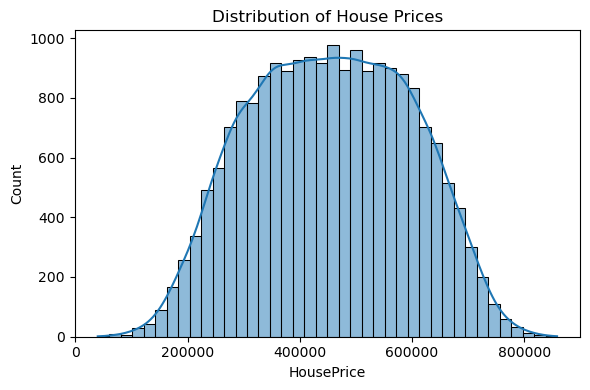

In [24]:
plt.figure(figsize=(6, 4))
sns.histplot(data["HousePrice"], bins=40, kde=True)
plt.title("Distribution of House Prices")
plt.tight_layout()
plt.show()

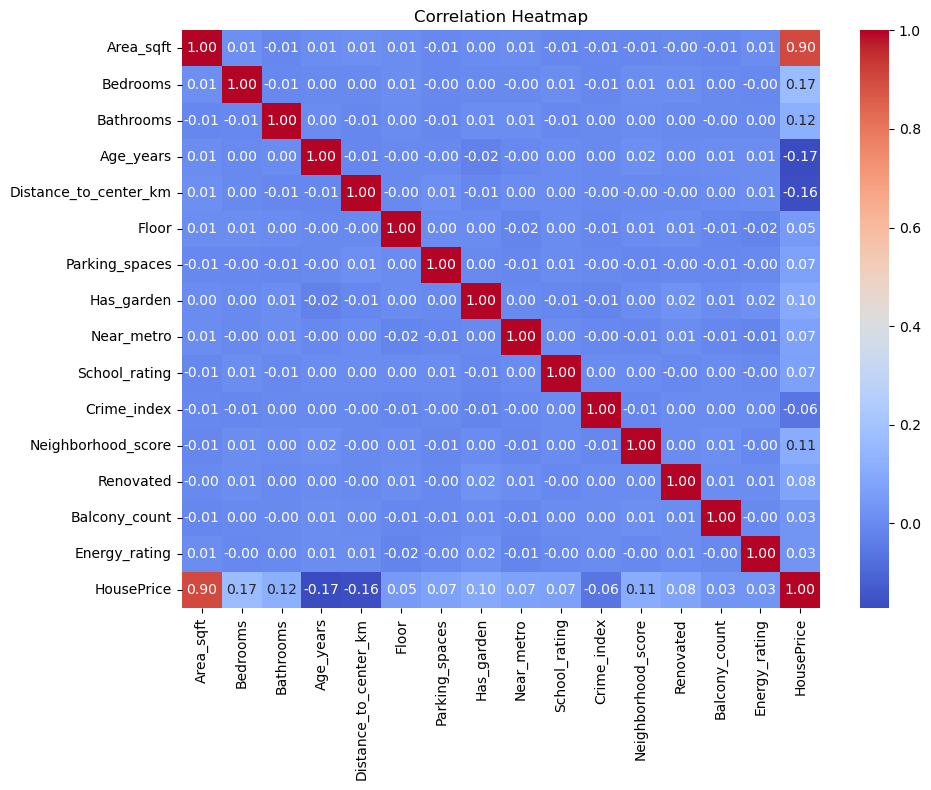

In [25]:
plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 4. Features / target and train-test split

In [26]:
# Drop the target column to get the features (axis=1 means "column")
X = data.drop(columns=["HousePrice"])
y = data["HousePrice"]

# Shuffle and split: 75% train, 25% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=44, shuffle=True
)

print("X_train shape:", X_train.shape)
print("X_test shape: ", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape: ", y_test.shape)

X_train shape: (15000, 15)
X_test shape:  (5000, 15)
y_train shape: (15000,)
y_test shape:  (5000,)


## 5. Baseline model: Linear Regression

In [27]:
LinearRegressionModel = LinearRegression(fit_intercept=True, copy_X=True, n_jobs=-1)
LinearRegressionModel.fit(X_train, y_train)

y_pred = LinearRegressionModel.predict(X_test)

## 6. Compare models with 5-fold cross-validation

In [28]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=44, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=44),
}

rows = []
for name, m in models.items():
    r2_scores = cross_val_score(m, X, y, cv=5, scoring="r2")
    rmse_scores = -cross_val_score(m, X, y, cv=5, scoring="neg_root_mean_squared_error")
    rows.append({
        "Model": name,
        "CV R2 (mean)": r2_scores.mean(),
        "CV R2 (std)": r2_scores.std(),
        "CV RMSE (mean)": rmse_scores.mean(),
    })

cv_results = pd.DataFrame(rows).sort_values("CV R2 (mean)", ascending=False).reset_index(drop=True)
cv_results

,Model,CV R2 (mean),CV R2 (std),CV RMSE (mean)
0,Ridge,0.969167,0.000606,24895.737875
1,Linear Regression,0.969167,0.000606,24895.738233
2,Gradient Boosting,0.954912,0.001437,30102.334630
3,Random Forest,0.937384,0.002614,35470.388342


**Takeaway:** write here which model won and why (for example: if Linear Regression is close to the tree models, the relationship between the features and the price is mostly linear, so the simpler model is the better choice).

## 7. Evaluate on the test set

In [29]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE : {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R2  : {r2:.4f}")

MAE : 19,647.84
RMSE: 24,543.44
R2  : 0.9703


## 8. Error analysis

In [30]:
comparison = pd.DataFrame({"Actual": y_test, "Prediction": y_pred})
comparison["Absolute_Error"] = (comparison["Actual"] - comparison["Prediction"]).abs()

print(comparison.head(10))
print()
print("Average error:", comparison["Absolute_Error"].mean())
print("Largest error:", comparison["Absolute_Error"].max())
print("Smallest error:", comparison["Absolute_Error"].min())

       Actual     Prediction  Absolute_Error
10498  256904  291984.111419    35080.111419
9798   344563  358647.941114    14084.941114
12826  433873  445423.532026    11550.532026
6298   344904  314446.165398    30457.834602
19040  417039  414319.613731     2719.386269
13232  460930  440725.577390    20204.422610
11320  265619  295010.156053    29391.156053
17423  321756  351034.221245    29278.221245
19447  503846  558159.817285    54313.817285
2088   321566  318453.993949     3112.006051

Average error: 19647.838517126613
Largest error: 111940.83609173796
Smallest error: 0.15421658789273351


In [31]:
# The 5 worst predictions
comparison.sort_values("Absolute_Error", ascending=False).head(5)

,Actual,Prediction,Absolute_Error
7206,748341,636400.163908,111940.836092
854,618777,522971.965804,95805.034196
1496,432874,338211.117372,94662.882628
3357,436106,342791.381623,93314.618377
9455,463381,374458.170395,88922.829605


## 9. Visualizations

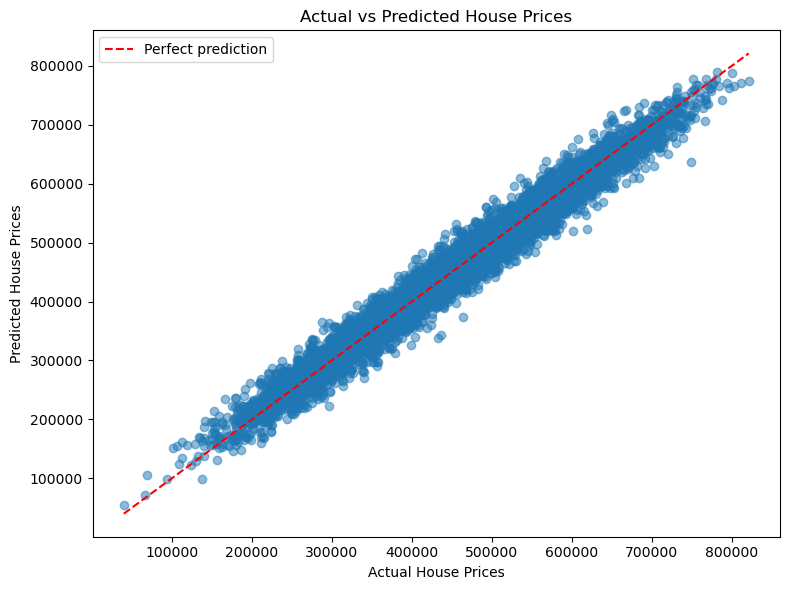

In [32]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, color="red", linestyle="--", label="Perfect prediction")
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.tight_layout()
plt.show()

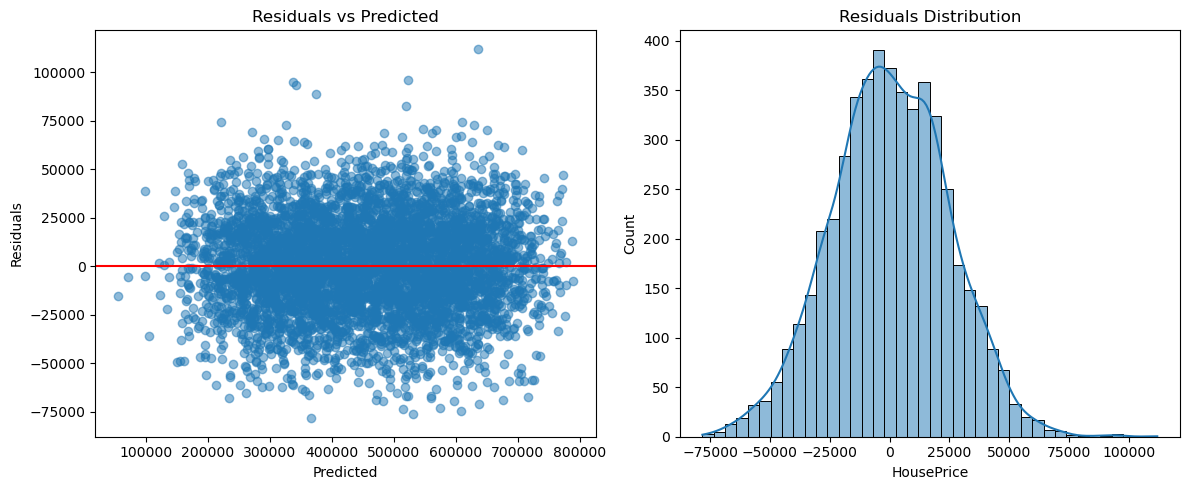

In [33]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_pred, residuals, alpha=0.5)
axes[0].axhline(0, color="red")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted")

sns.histplot(residuals, bins=40, kde=True, ax=axes[1])
axes[1].set_title("Residuals Distribution")

plt.tight_layout()
plt.show()

## 10. Feature importance (model coefficients)

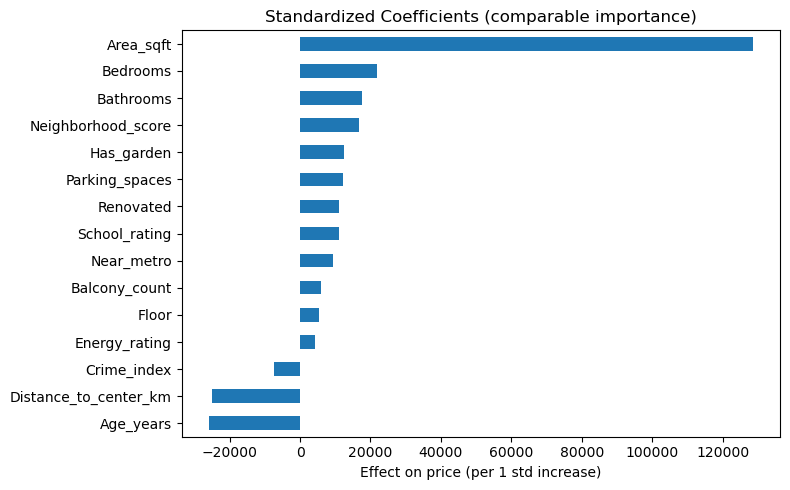

In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)
scaled_model = LinearRegression().fit(X_scaled, y_train)

coef = pd.Series(scaled_model.coef_, index=X.columns).sort_values()
plt.figure(figsize=(8, 5))
coef.plot(kind="barh")
plt.title("Standardized Coefficients (comparable importance)")
plt.xlabel("Effect on price (per 1 std increase)")
plt.tight_layout()
plt.show()

**Note:** coefficients are directly comparable only if the features are on a similar scale. If they are not, standardize the features first (for example with `StandardScaler`) before comparing their importance.

## 11. Save the model

In [35]:
joblib.dump(LinearRegressionModel, "house_price_model.joblib")

# To load it later:
# model = joblib.load("house_price_model.joblib")
# model.predict(new_data)

['house_price_model.joblib']

# 12. Conclusion

- Best model: *(fill in)*
- Test R2: *(fill in)*, MAE: *(fill in)*
- Most influential features: *(fill in)*
- Next steps: feature engineering, hyperparameter tuning, testing on real-world data.
- 